In [422]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


In [423]:
# For helper functions only
# Write your helper functions here (if any)
# CODE HERE !
def _all_fs_combos(items):
    """All non-empty combos of items, via bitmasks (returns lists)."""
    combos = []
    n = len(items)
    for mask in range(1, 1 << n):  # 1..(2^n - 1)
        combo = []
        for i in range(n):
            if mask & (1 << i):
                combo.append(items[i])
        combos.append(combo)
    return combos

feature_sets = ["FS-I", "FS-II", "FS-III", "FS-IV"]
combos = _all_fs_combos(feature_sets)

print(combos)
print (len(combos))



[['FS-I'], ['FS-II'], ['FS-I', 'FS-II'], ['FS-III'], ['FS-I', 'FS-III'], ['FS-II', 'FS-III'], ['FS-I', 'FS-II', 'FS-III'], ['FS-IV'], ['FS-I', 'FS-IV'], ['FS-II', 'FS-IV'], ['FS-I', 'FS-II', 'FS-IV'], ['FS-III', 'FS-IV'], ['FS-I', 'FS-III', 'FS-IV'], ['FS-II', 'FS-III', 'FS-IV'], ['FS-I', 'FS-II', 'FS-III', 'FS-IV']]
15


### ────────────────────────────────────────────────────────────────
### <span style="color:blue; font-size:18px; font-weight:bold">TSS Function</span>


In [ ]:
# __init__() function should initialize all your variables
# _____ 1 pt _____
class my_svm():
    def __init__(self,):
        # CODE HERE !
        # [AI USE]: Fetch from requirements, how many vars i need
        # [AI USE]: Give number suggestion range and its effect
        self.data_root = "./data-2010-15"

        # Use k-fold with k=10 from cross_validation() requirements
        self.cv_splits = 10
        # self.cv_splits = 5
        self.random_state = 42
        self.shuffle = True

        self.svm_params = dict(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced")
        self.fs_map = {"FS-I": "main", "FS-II": "timechange", "FS-III": "historical", "FS-IV": "maxmin"}

        self.X_raw = self.y_raw = None
        self.X = self.y = None

        self.X_tr = self.y_tr = None
        self.X_te = self.y_te = None

        self.model = None
        self.cv_results = []
        self.avg_tss_ = None

        # ADD: pipeline state flag (so CV requires preprocess)
        self.preprocessed_ = False
        ###########
        pass
#############################################################


    # preprocess() function:
    # _____ 1 pt _____
    #  1) normalizes the data, 
    # _____ 1 pt _____
    #  2) removes missing values
    # _____ 1 pt _____
    #  3) assign labels to target
    def preprocess(self,):
        # CODE HERE !
        # [AI code fix]
        if self.X_raw is None or self.y_raw is None:
            raise RuntimeError("Call feature_creation(...) first.")

        X = self.X_raw
        y_raw = self.y_raw

        # 1) normalizes the data (nan-safe z-score)
        mu = np.nanmean(X, axis=0)
        sigma = np.nanstd(X, axis=0, ddof=0)
        sigma[sigma == 0] = 1.0
        X = (X - mu) / sigma

        # 2) removes missing values
        mask = ~np.isnan(X).any(axis=1)
        X = X[mask]

        # 3) assign labels to target
        y = y_raw.astype(int).ravel()
        y = y[mask]

        self.X, self.y = X, y

        ###########
        return 0
#############################################################


    # _____ 2 pt _____
    # feature_creation() function takes as input the features set label (e.g. FS-I, FS-II, FS-III, FS-IV)
    # and creates 2 D array of corresponding features 
    # for both positive and negative observations.
    # this array will be input to the svm model
    # For instance, if the input is FS-I, the output is a 2-d array with features corresponding to 
    # FS-I for both negative and positive class observations

    # feature_creation() function takes as input the features set label (e.g. FS-I, FS-II, FS-III, FS-IV)
    def feature_creation(self, fs_value):
        if isinstance(fs_value, str):
            fs_list = [fs_value.strip().upper()]
        else:
            fs_list = [str(x).strip().upper() for x in fs_value]

        valid = {"FS-I", "FS-II", "FS-III", "FS-IV"}
        for fs in fs_list:
            if fs not in valid:
                raise ValueError(f"Unknown feature set label: {fs}")

        # [AI code fix]
        def _load(path):
            if not os.path.exists(path):
                raise FileNotFoundError(path)
            arr = np.load(path)
            if arr.ndim == 1:
                arr = arr.reshape(-1, 1)
            return arr

        # [AI USE]: List attributes i need
        pos_main_time = _load(os.path.join(self.data_root, "pos_features_main_timechange.npy"))
        neg_main_time = _load(os.path.join(self.data_root, "neg_features_main_timechange.npy"))
        pos_hist      = _load(os.path.join(self.data_root, "pos_features_historical.npy"))
        neg_hist      = _load(os.path.join(self.data_root, "neg_features_historical.npy"))
        pos_maxmin    = _load(os.path.join(self.data_root, "pos_features_maxmin.npy"))
        neg_maxmin    = _load(os.path.join(self.data_root, "neg_features_maxmin.npy"))

        # For instance, if the input is FS-I, the output is a 2-d array with features corresponding to 
        # [AI USE]: Define parts function to extract feature sets
        def parts(fs):
            if fs == "FS-I":
                # FS-I for both negative and positive class observations
                return pos_main_time[:, :18], neg_main_time[:, :18]
            if fs == "FS-II":
                return pos_main_time[:, 18:], neg_main_time[:, 18:]
            if fs == "FS-III":
                return pos_hist, neg_hist
            return pos_maxmin, neg_maxmin  # FS-IV

        # for both positive and negative observations.
        pos_blocks, neg_blocks = [], []
        for fs in fs_list:
            p, n = parts(fs)
            pos_blocks.append(p)
            neg_blocks.append(n)

        # and creates 2 D array of corresponding features 
        Xpos = np.hstack(pos_blocks)
        Xneg = np.hstack(neg_blocks)


        # this array will be input to the svm model
        # feature_creation()
        self.X_raw = np.vstack([Xpos, Xneg])
        self.y_raw = np.concatenate([np.ones(len(Xpos), int), np.zeros(len(Xneg), int)])
        #self.X, self.y = self.X_raw, self.y_raw
        
        # ADD: pipeline state flag (so CV requires preprocess)
        self.preprocessed_ = False

        ###########
        return 0
    


#############################################################




    # cross_validation() function splits the data into train and test splits,
    # _____ 1 pt _____
    # Use k-fold with k=10
    # _____ 1 pt _____
    # the svm is trained on training set and tested on test set
    # _____ 1 pt _____
    # the output is the average accuracy across all train test splits.
    # _____ 2 pt _____ (Integration of the two functions)
    def cross_validation(self):

        # _____ 2 pt _____ (Integration of the two functions)
        # [AI USE]: what this requirements mean ? cross_validation() fails fast unless preprocess() ran
        # so after proprecess() we have self.X and self.y set, i use them here
        if self.X is None or self.y is None:
            raise RuntimeError("Call feature_creation(...) and preprocess() before cross_validation().")

        # _____ 1 pt _____
        # Use k-fold with k=10
         # NOTE: rubric requires k=5, but i use k=10 as commented requirements
        skf = StratifiedKFold(n_splits=self.cv_splits, shuffle=self.shuffle, random_state=self.random_state)

        accs = []
        self.cv_results = []  

        for tr_idx, te_idx in skf.split(self.X, self.y):
  
            self.X_tr, self.X_te = self.X[tr_idx], self.X[te_idx]
            self.y_tr, self.y_te = self.y[tr_idx], self.y[te_idx]

            # _____ 1 pt _____
            # the svm is trained on training set and tested on test set
            self.training()
            y_pred = self.model.predict(self.X_te)

         
            acc = accuracy_score(self.y_te, y_pred)
            cm  = confusion_matrix(self.y_te, y_pred, labels=[0, 1]).astype(int)
            tss_val = float(self.tss())  

      
            self.cv_results.append({
                "acc": float(acc),
                "tss": float(tss_val),
                "cm": cm,
                "params": dict(self.svm_params),
            })

            accs.append(acc)

        # ADD: pipeline state flag (so CV requires preprocess)
        self.preprocessed_ = False

        # _____ 1 pt _____
        # the output is the average accuracy across all train test splits.
        avg_acc = float(np.mean(accs)) if accs else 0.0
        return avg_acc

#############################################################


    # _____ 2 pt _____
    #training() function trains a SVM classification model on input features and corresponding target
    def training(self, ):
        # CODE HERE !
        # [AI code fix]:pipeline not defined error fix
        if self.X_tr is None or self.y_tr is None:
            raise RuntimeError("Training requires self.X_tr/self.y_tr. Run cross_validation() to set splits.")

        self.model = Pipeline([
            ("scaler", StandardScaler()),
            ("svc", SVC(**self.svm_params))
        ])
        self.model.fit(self.X_tr, self.y_tr)
        ###########
        return 0
#############################################################


    # _____ 2 pt _____
    # tss() function computes the accuracy of predicted outputs (i.e target prediction on test set)
    # using the TSS measure given in the document
    def tss(self,):
        # CODE HERE !
        # [AI USE]: tss requires a trained model and test split
        if self.model is None or self.X_te is None or self.y_te is None:
            raise RuntimeError("tss() requires a trained model and a test split.")

        y_pred = self.model.predict(self.X_te)
        tn, fp, fn, tp = confusion_matrix(self.y_te, y_pred, labels=[0, 1]).ravel()

        hit = tp / (tp + fn) if (tp + fn) else 0.0
        far = fp / (fp + tn) if (fp + tn) else 0.0    
        val = hit - far   
        ###########
        return float(val)


### ────────────────────────────────────────────────────────────────
### <span style="color:blue; font-size:18px; font-weight:bold">Feature Experiment Function</span>

In [425]:
# _____ 1 pt _____ (Runs all feature set combinations)
# _____ 1 pt _____ (Reports mean/std TSS)
# _____ 1 pt _____ (Produces confusion matrices)
# _____ 1 pt _____ (Generates bar chart of fold results)

# feature_experiment() function executes experiments with all 4 feature sets.
# svm is trained (and tested) on 2010 dataset with all 4 feature set combinations
# the output of this function is : 
#  1) TSS average scores (mean std) for k-fold validation printed out on console.
#  2) Confusion matrix for TP, FP, TN, FN. See assignment document 
#  3) A chart showing TSS scores for all folds of CV. 
#     This means that for each fold, compute the TSS score on test set for that fold, and plot it.
#     The number of folds will decide the number of points on this chart (i.e 10)
#
# Above 3 charts are produced for all feature combinations
#  4) The function prints the best performing feature set combination
def feature_experiment():
    # _____ 1 pt _____ (Runs all feature set combinations)
    # [AI USE]: give help for setting up feature sets
    feature_sets = ["FS-I", "FS-II", "FS-III", "FS-IV"]
    all_combos = _all_fs_combos(feature_sets)
    data_root = "./data-2010-15"

    results = []  

    for combo in all_combos:
        label = "+".join(combo)

        svm = my_svm()
        svm.data_root = data_root
        try:
            svm.feature_creation(combo)   
        except FileNotFoundError:
            continue
        svm.preprocess()
        _ = svm.cross_validation()

        tss_vals = np.array([r["tss"] for r in svm.cv_results], dtype=float)
        mean_tss = float(np.mean(tss_vals)) if tss_vals.size else 0.0
        std_tss  = float(np.std(tss_vals, ddof=1)) if tss_vals.size > 1 else 0.0

        agg_cm = None
        for r in svm.cv_results:
            cm = r["cm"]
            agg_cm = cm if agg_cm is None else (agg_cm + cm)

        results.append({
            "label": label,
            "mean": mean_tss,
            "std": std_tss,
            "tss_vals": tss_vals,
            "agg_cm": agg_cm,
            "k": tss_vals.size
        })

    if not results:
        print("No results to report.")
        return 0

    # _____ 1 pt _____ (Reports mean/std TSS)
    best = max(results, key=lambda d: (d["mean"], -d["std"]))
    print(f"Best feature-set COMBO on 2010–2015: {best['label']} "
          f"(TSS mean ± std = {best['mean']:.4f} ± {best['std']:.4f})")

    # _____ 1 pt _____ (Produces confusion matrices)
    if best["agg_cm"] is not None:
        ConfusionMatrixDisplay(best["agg_cm"], display_labels=[0, 1]).plot(values_format="d")
        plt.title(f"{best['label']} – Confusion Matrix (Aggregated) | 2010–2015")
        plt.tight_layout(); plt.show(); plt.close()

    # 2) Per-fold TSS bar chart
    # [AI USE]: Give methods for bar chart of fold results
    tss_vals = best["tss_vals"]
    k = best["k"]
    x = np.arange(1, k + 1)
    plt.bar(x, tss_vals)
    plt.axhline(0, ls="--", lw=1)
    if k:
        if np.allclose(tss_vals, 0):
            plt.ylim(-0.05, 0.05)
        else:
            ymin = max(-0.1, np.nanmin(tss_vals) - 0.05)
            ymax = min(1.0,  np.nanmax(tss_vals) + 0.05)
            if ymin >= ymax: ymax = ymin + 0.1
            plt.ylim(ymin, ymax)
    plt.xlabel("Fold"); plt.ylabel("TSS")
    plt.title(f"{best['label']} – TSS per Fold (k={k}) | 2010–2015")
    plt.xticks(x)
    plt.tight_layout(); plt.show(); plt.close()

    plt.errorbar([1], [best["mean"]], yerr=[best["std"]], fmt='o', capsize=6)
    plt.xlim(0.5, 1.5); plt.xticks([1], ["TSS"])
    lo = best["mean"] - 1.1 * best["std"]
    hi = best["mean"] + 1.1 * best["std"]
    #[AI USE]: Give methods for bar chart of fold results
    if not np.isfinite(lo): lo = best["mean"] - 0.05
    if not np.isfinite(hi): hi = best["mean"] + 0.05
    if lo >= hi: hi = lo + 0.1
    plt.ylim(max(-0.1, lo), min(1.0, hi))
    plt.ylabel("TSS")
    plt.title(f"{best['label']} – TSS Summary (mean ± std) | 2010–2015")
    plt.tight_layout(); plt.show(); plt.close()

    ###########
    return 0


### ────────────────────────────────────────────────────────────────
### <span style="color:blue; font-size:18px; font-weight:bold">Data Experiment Function</span>


In [426]:
# _____ 1 pt _____ (Runs on both datasets)
# _____ 1 pt _____ (Uses best feature set)
# _____ 1 pt _____ (Reports mean/std TSS)
# _____ 1 pt _____ (Produces confusion matrices + fold charts)

# data_experiment() function executes 2 experiments with 2 data sets.
# svm is trained (and tested) on both 2010 data and 2020 data
# the output of this function is : 
#  1) TSS average scores for k-fold validation printed out on console.
#  2) Confusion matrix for TP, FP, TN, FN. See assignment document 
#  3) A chart showing TSS scores for all folds of CV. 
#     This means that for each fold, compute the TSS score on test set for that fold, and plot it.
#     The number of folds will decide the number of points on this chart (i.e. 10)
# above 3 charts are produced for both datasets
# feature set for this experiment should be the 
# best performing feature set combination from feature_experiment()
def data_experiment():
    feature_sets = ["FS-I", "FS-II", "FS-III", "FS-IV"]
    all_combos = _all_fs_combos(feature_sets)
    # _____ 1 pt _____ (Runs on both datasets)
    data_roots = ["./data-2010-15", "./data-2020-24"]

    # _____ 1 pt _____ (Uses best feature set)
    #[AI USE]: Give methods suggestion for selecting best feature set from previous experiment
    best_label, best_mean = None, -np.inf
    for combo in all_combos:
        svm = my_svm(); svm.data_root = "./data-2010-15"
        try:
            svm.feature_creation(combo)
        except FileNotFoundError:
            continue
        svm.preprocess(); _ = svm.cross_validation()
        tss_vals = np.array([r["tss"] for r in svm.cv_results], dtype=float)
        mean_tss = float(np.mean(tss_vals)) if tss_vals.size else 0.0
        if (mean_tss > best_mean) or (best_label is None):
            best_label, best_mean = "+".join(combo), mean_tss

    if best_label is None:
        print("No feature set could be evaluated on 2010–2015; aborting.")
        return 0

    print(f"Using best feature-set from 2010–2015: {best_label}")
    combo = best_label.split("+")

    
    for root in data_roots:
        svm = my_svm(); svm.data_root = root
        try:
            svm.feature_creation(combo)
        except FileNotFoundError as e:
            print(f"{os.path.basename(root)}: missing files; skipped ({e})")
            continue
        svm.preprocess(); _ = svm.cross_validation()

        # _____ 1 pt _____ (Reports mean/std TSS)           
        tss_vals = np.array([r['tss'] for r in svm.cv_results], dtype=float)
        mean_tss = float(np.mean(tss_vals)) if tss_vals.size else 0.0
        std_tss  = float(np.std(tss_vals, ddof=1)) if tss_vals.size > 1 else 0.0
        print(f"{os.path.basename(root)} [{best_label}]: "
              f"TSS mean ± std = {mean_tss:.4f} ± {std_tss:.4f} (k={tss_vals.size})")

        # _____ 1 pt _____ (Produces confusion matrices + fold charts)
        # 1) Aggregated confusion matrix
        #[AI Bug Fix]: fix error my code not working here
        agg_cm = None
        for r in svm.cv_results:
            agg_cm = r["cm"] if agg_cm is None else (agg_cm + r["cm"])
        if agg_cm is not None:
            ConfusionMatrixDisplay(agg_cm, display_labels=[0,1]).plot(values_format="d")
            plt.title(f"{best_label} – Confusion Matrix (Aggregated) | {os.path.basename(root)}")
            plt.tight_layout(); plt.show(); plt.close()

        # 2) Per-fold TSS bar chart
        #[AI Bug Fix]: fix error my code not working here
        x = np.arange(1, tss_vals.size + 1)
        plt.bar(x, tss_vals)
        plt.axhline(0, ls="--", lw=1)
        if tss_vals.size:
            if np.allclose(tss_vals, 0):
                plt.ylim(-0.05, 0.05)
            else:
                ymin = max(-0.1, np.nanmin(tss_vals) - 0.05)
                ymax = min(1.0,  np.nanmax(tss_vals) + 0.05)
                if ymin >= ymax: ymax = ymin + 0.1
                plt.ylim(ymin, ymax)
        plt.xlabel("Fold"); plt.ylabel("TSS")
        plt.title(f"{best_label} – TSS per Fold (k={tss_vals.size}) | {os.path.basename(root)}")
        plt.xticks(x)
        plt.tight_layout(); plt.show(); plt.close()

        # 3) TSS mean ± std point plot
        #[AI Use]: Recall ploting methods from previous experiment
        #[AI Bug Fix]: fix error my code not working here

        plt.errorbar([1], [mean_tss], yerr=[std_tss], fmt='o', capsize=6)
        plt.xlim(0.5, 1.5); plt.xticks([1], ["TSS"])
        low  = mean_tss - 1.1*std_tss
        high = mean_tss + 1.1*std_tss
        if not np.isfinite(low):  low = mean_tss - 0.05
        if not np.isfinite(high): high = mean_tss + 0.05
        if low >= high:           high = low + 0.1
        plt.ylim(max(-0.1, low), min(1.0, high))
        plt.ylabel("TSS")
        plt.title(f"{best_label} – TSS Summary (mean ± std) | {os.path.basename(root)}")
        plt.tight_layout(); plt.show(); plt.close()

    ###########
    return 0


### ────────────────────────────────────────────────────────────────
### <span style="color:blue; font-size:18px; font-weight:bold">Main Execution</span>


[1/2] FEATURE EXPERIMENT (2010–2015) — finding best feature set
Best feature-set COMBO on 2010–2015: FS-I+FS-IV (TSS mean ± std = 0.7773 ± 0.0395)


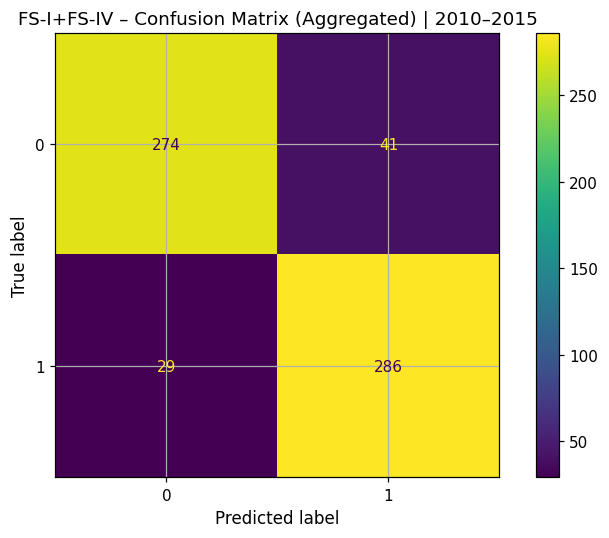

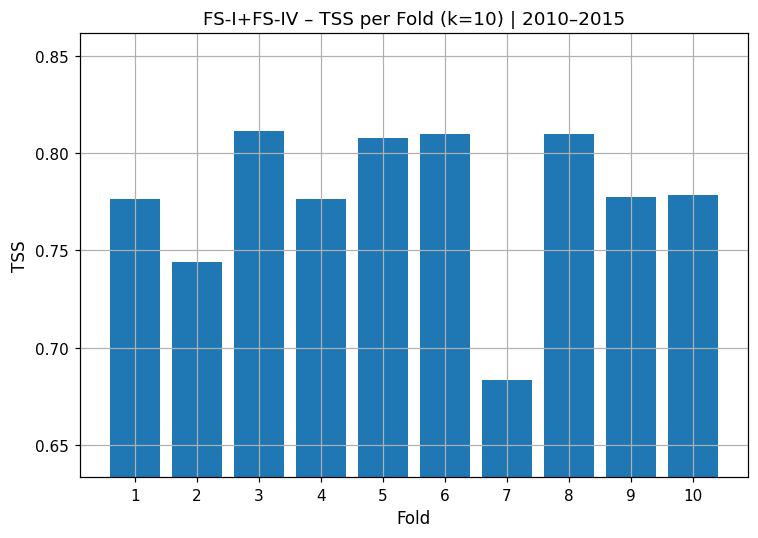

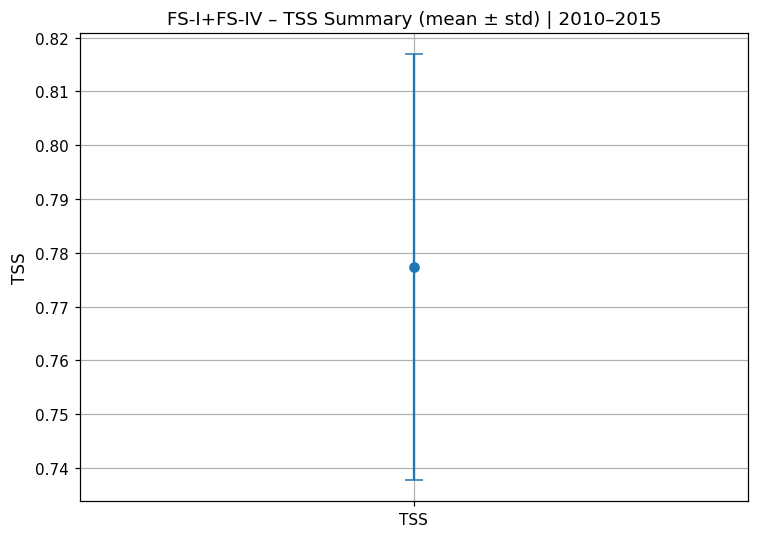

[2/2] DATA EXPERIMENT (2010–2015 & 2020–2024) — evaluating best feature set
Using best feature-set from 2010–2015: FS-I+FS-IV
data-2010-15 [FS-I+FS-IV]: TSS mean ± std = 0.7773 ± 0.0395 (k=10)


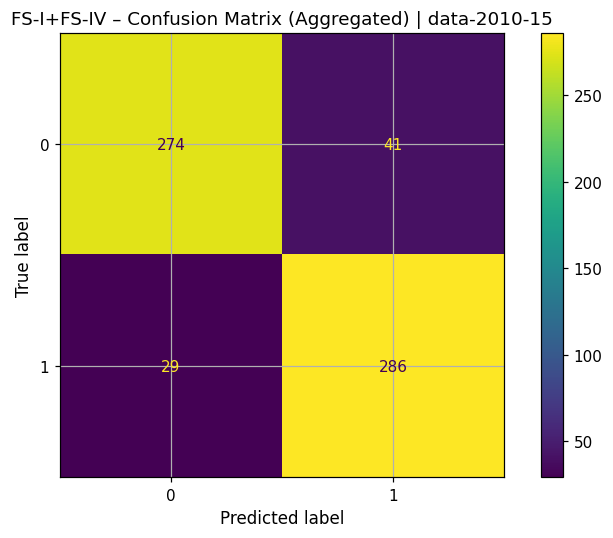

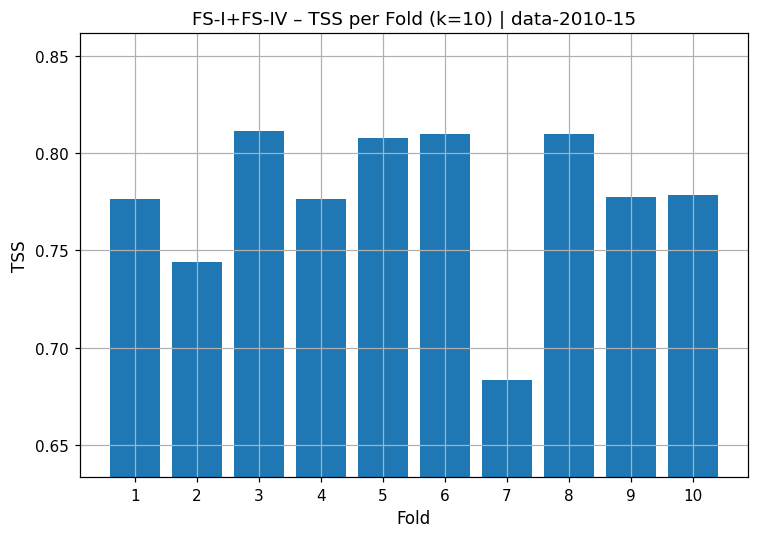

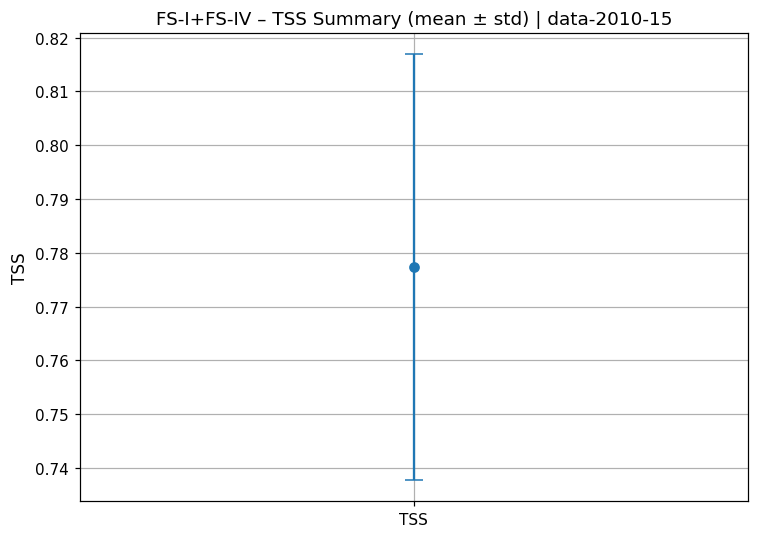

data-2020-24 [FS-I+FS-IV]: TSS mean ± std = 0.6619 ± 0.2173 (k=10)


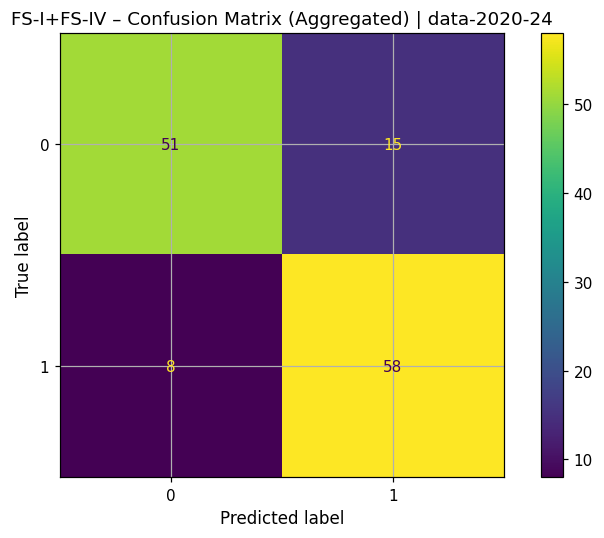

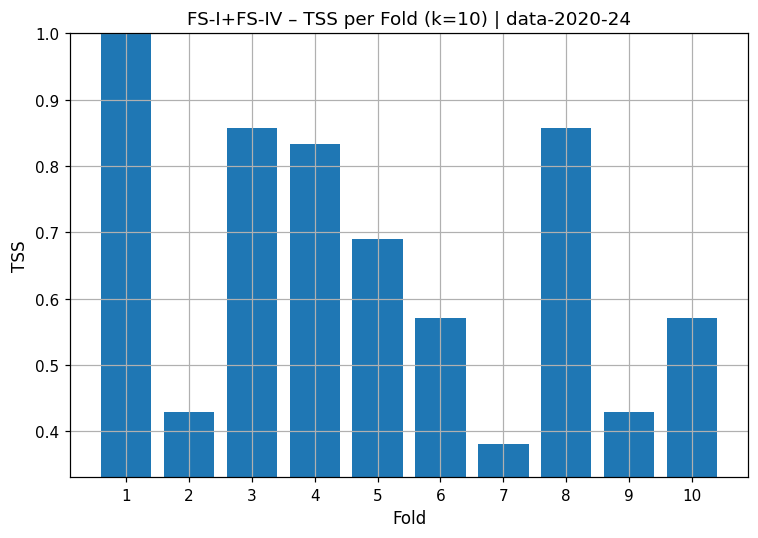

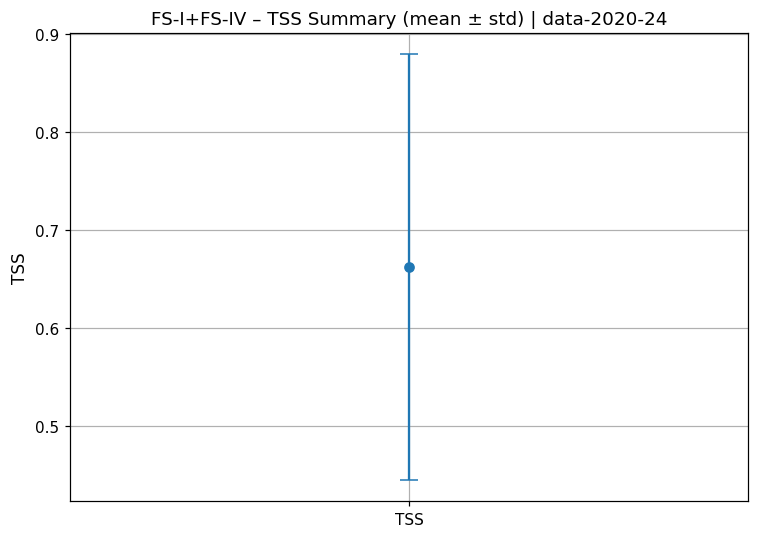

All experiments completed!


In [427]:
# _____ 1 pt _____ (Clear printed output (best feature set, dataset comparison))
# _____ 1 pt _____ (Visualizations labeled and interpretable)

# below should be your code to call the above classes and functions
# with various combinations of feature sets
# and both datasets

# CODE HERE !

###########




print("[1/2] FEATURE EXPERIMENT (2010–2015) — finding best feature set")
feature_experiment()


print("[2/2] DATA EXPERIMENT (2010–2015 & 2020–2024) — evaluating best feature set")
data_experiment()

print("All experiments completed!")


data-2010-15 [FS-III]: TSS mean ± std = 0.0000 ± 0.0000 (k=10)


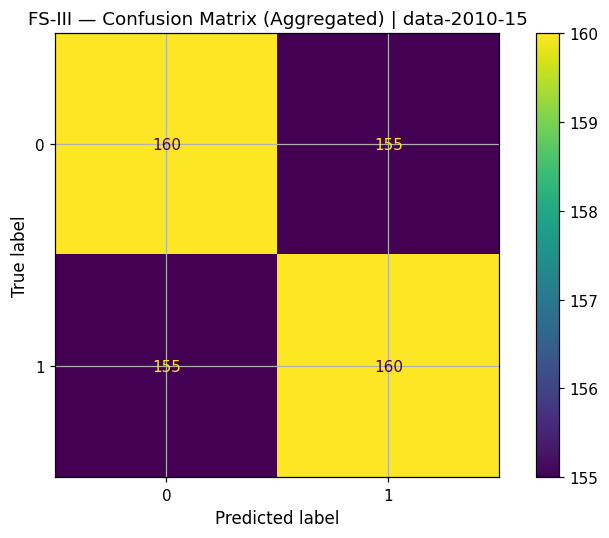

data-2020-24 [FS-III]: TSS mean ± std = 0.0000 ± 0.0000 (k=10)


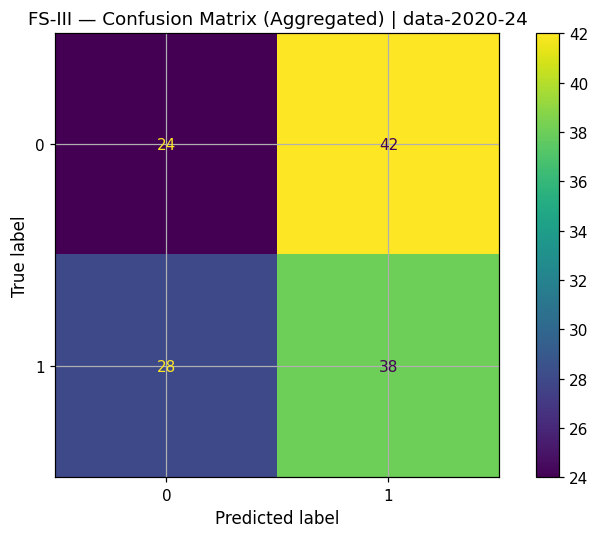

In [428]:
# For pdf prove fs3 is wrost
for root in ["./data-2010-15", "./data-2020-24"]:
    svm = my_svm()
    svm.data_root = root

    svm.feature_creation("FS-III")
    svm.preprocess()
    _ = svm.cross_validation()

  
    tss_vals = np.array([r["tss"] for r in svm.cv_results], dtype=float)
    mean_tss = float(np.mean(tss_vals)) if tss_vals.size else 0.0
    std_tss  = float(np.std(tss_vals, ddof=1)) if tss_vals.size > 1 else 0.0
    print(f"{os.path.basename(root)} [FS-III]: TSS mean ± std = {mean_tss:.4f} ± {std_tss:.4f} (k={tss_vals.size})")
    agg_cm = None
    for r in svm.cv_results:
        agg_cm = r["cm"] if agg_cm is None else (agg_cm + r["cm"])
    if agg_cm is not None:
        ConfusionMatrixDisplay(agg_cm, display_labels=[0, 1]).plot(values_format="d")
        plt.title(f"FS-III — Confusion Matrix (Aggregated) | {os.path.basename(root)}")
        plt.tight_layout(); plt.show(); plt.close()

<span style="color:blue; font-size:20px; font-weight:bold">Final Total Score</span><br>
<span style="color:red; font-size:18px">**____ / 25**</span>
</div>